In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from matplotlib.pyplot import xticks
from matplotlib.pyplot import yticks

In [2]:
pd.set_option('display.max.rows', 375) 

In [3]:
df = pd.DataFrame(pd.read_csv("Salary Data.csv"))
df

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


In [4]:
df.shape

(375, 6)

In [5]:
df.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


In [6]:
df.isna().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [7]:
df = df.dropna()

In [8]:
df.isna().sum()

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

In [9]:
df.columns

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='str')

In [10]:
df.shape

(373, 6)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 373 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    str    
 2   Education Level      373 non-null    str    
 3   Job Title            373 non-null    str    
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), str(3)
memory usage: 20.4 KB


In [12]:
# Checking Null values
df.isnull().sum()
# There are no NULL values in the dataset, hence it is clean.

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

In [13]:
len(set(df['Job Title']))

174

In [14]:
auto=df[['Age', 'Gender', 'Education Level', 'Years of Experience','Salary']]

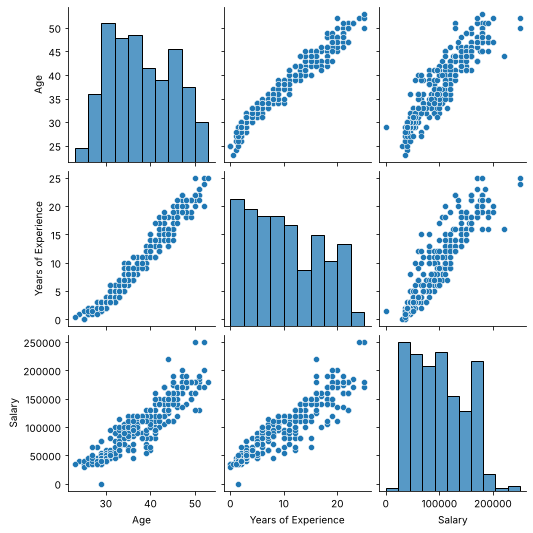

In [15]:
sns.pairplot(auto)

In [16]:
auto_numeric = auto.select_dtypes(include=np.number)
auto_numeric.corr()


,Age,Years of Experience,Salary
Age,1.000000,0.979128,0.922335
Years of Experience,0.979128,1.000000,0.930338
Salary,0.922335,0.930338,1.000000


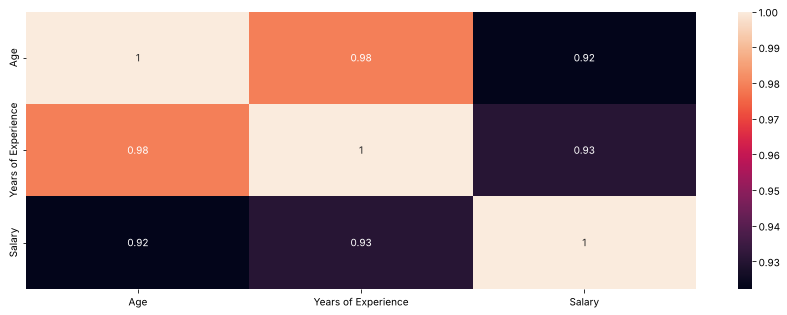

In [17]:
# Starting machine learning
import seaborn as sns
plt.figure(figsize=(15,5))
sns.heatmap(auto_numeric.corr(),annot=True)
plt.show()

In [18]:
auto

,Age,Gender,Education Level,Years of Experience,Salary
0,32.0,Male,Bachelor's,5.0,90000.0
1,28.0,Female,Master's,3.0,65000.0
2,45.0,Male,PhD,15.0,150000.0
3,36.0,Female,Bachelor's,7.0,60000.0
4,52.0,Male,Master's,20.0,200000.0
5,29.0,Male,Bachelor's,2.0,55000.0
6,42.0,Female,Master's,12.0,120000.0
7,31.0,Male,Bachelor's,4.0,80000.0
8,26.0,Female,Bachelor's,1.0,45000.0
9,38.0,Male,PhD,10.0,110000.0


In [19]:
# Dimension reduction

In [20]:
gender = pd.get_dummies(auto['Gender'], drop_first = True)
gender

,Male
0,True
1,False
2,True
3,False
4,True
5,True
6,False
7,True
8,False
9,True


In [21]:
auto = pd.concat([auto, gender], axis = 1)
auto

,Age,Gender,Education Level,Years of Experience,Salary,Male
0,32.0,Male,Bachelor's,5.0,90000.0,True
1,28.0,Female,Master's,3.0,65000.0,False
2,45.0,Male,PhD,15.0,150000.0,True
3,36.0,Female,Bachelor's,7.0,60000.0,False
4,52.0,Male,Master's,20.0,200000.0,True
5,29.0,Male,Bachelor's,2.0,55000.0,True
6,42.0,Female,Master's,12.0,120000.0,False
7,31.0,Male,Bachelor's,4.0,80000.0,True
8,26.0,Female,Bachelor's,1.0,45000.0,False
9,38.0,Male,PhD,10.0,110000.0,True


In [22]:
education = pd.get_dummies(auto['Education Level'], drop_first = False)
education

,Bachelor's,Master's,PhD
0,True,False,False
1,False,True,False
2,False,False,True
3,True,False,False
4,False,True,False
5,True,False,False
6,False,True,False
7,True,False,False
8,True,False,False
9,False,False,True


In [23]:
auto = pd.concat([auto, education], axis = 1)
auto

,Age,Gender,Education Level,Years of Experience,Salary,Male,Bachelor's,Master's,PhD
0,32.0,Male,Bachelor's,5.0,90000.0,True,True,False,False
1,28.0,Female,Master's,3.0,65000.0,False,False,True,False
2,45.0,Male,PhD,15.0,150000.0,True,False,False,True
3,36.0,Female,Bachelor's,7.0,60000.0,False,True,False,False
4,52.0,Male,Master's,20.0,200000.0,True,False,True,False
5,29.0,Male,Bachelor's,2.0,55000.0,True,True,False,False
6,42.0,Female,Master's,12.0,120000.0,False,False,True,False
7,31.0,Male,Bachelor's,4.0,80000.0,True,True,False,False
8,26.0,Female,Bachelor's,1.0,45000.0,False,True,False,False
9,38.0,Male,PhD,10.0,110000.0,True,False,False,True


In [24]:
auto = auto.drop(['Gender','Education Level'],axis = 1)
auto

,Age,Years of Experience,Salary,Male,Bachelor's,Master's,PhD
0,32.0,5.0,90000.0,True,True,False,False
1,28.0,3.0,65000.0,False,False,True,False
2,45.0,15.0,150000.0,True,False,False,True
3,36.0,7.0,60000.0,False,True,False,False
4,52.0,20.0,200000.0,True,False,True,False
5,29.0,2.0,55000.0,True,True,False,False
6,42.0,12.0,120000.0,False,False,True,False
7,31.0,4.0,80000.0,True,True,False,False
8,26.0,1.0,45000.0,False,True,False,False
9,38.0,10.0,110000.0,True,False,False,True


In [25]:
auto.corr()

,Age,Years of Experience,Salary,Male,Bachelor's,Master's,PhD
Age,1.000000,0.979128,0.922335,-0.020324,-0.541733,0.281897,0.411183
Years of Experience,0.979128,1.000000,0.930338,0.002884,-0.573775,0.306961,0.424752
Salary,0.922335,0.930338,1.000000,0.071106,-0.657181,0.362061,0.473073
Male,-0.020324,0.002884,0.071106,1.000000,0.049259,-0.036219,-0.023827
Bachelor's,-0.541733,-0.573775,-0.657181,0.049259,1.000000,-0.731944,-0.487964
Master's,0.281897,0.306961,0.362061,-0.036219,-0.731944,1.000000,-0.237577
PhD,0.411183,0.424752,0.473073,-0.023827,-0.487964,-0.237577,1.000000


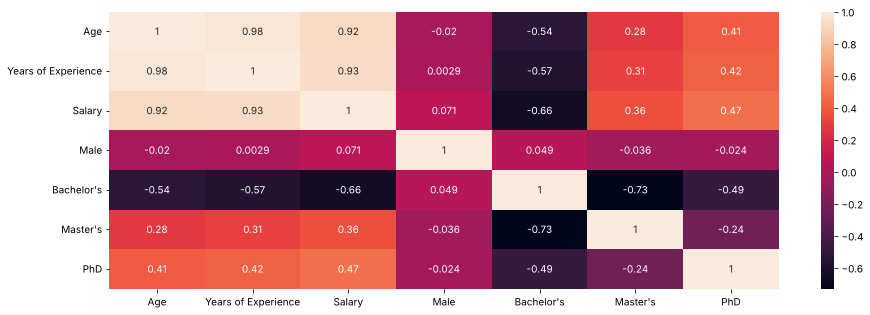

In [26]:
# Starting machine learning
import seaborn as sns
plt.figure(figsize=(15,5))
sns.heatmap(auto.corr(),annot=True)
plt.show()

In [27]:
auto = auto.drop(['Male'],axis = 1)
auto

,Age,Years of Experience,Salary,Bachelor's,Master's,PhD
0,32.0,5.0,90000.0,True,False,False
1,28.0,3.0,65000.0,False,True,False
2,45.0,15.0,150000.0,False,False,True
3,36.0,7.0,60000.0,True,False,False
4,52.0,20.0,200000.0,False,True,False
5,29.0,2.0,55000.0,True,False,False
6,42.0,12.0,120000.0,False,True,False
7,31.0,4.0,80000.0,True,False,False
8,26.0,1.0,45000.0,True,False,False
9,38.0,10.0,110000.0,False,False,True


In [28]:
from sklearn.model_selection import train_test_split
# We specify this so that the train and test data set always have the same rows, respectively
df_train, df_test = train_test_split(auto, train_size = 0.85, test_size = 0.15, random_state = 1)

In [29]:
df_train.shape

(317, 6)

In [30]:
df_test.shape

(56, 6)

In [31]:
from sklearn.linear_model import LinearRegression
X_train = df_train[['Age','Years of Experience',"Bachelor's",
                    "Master's","PhD"]]
y_train = df_train['Salary']

lm = LinearRegression()
model = lm.fit(X_train, y_train)


In [32]:
data = df_test.iloc[10:11]
actual_salary = data['Salary']
data = data.drop(['Salary'],axis = 1)
data

,Age,Years of Experience,Bachelor's,Master's,PhD
314,35.0,8.0,True,False,False


In [33]:
print("Predicted Salary",model.predict(data))
print("Actual Salary",actual_salary)

Predicted Salary [80297.64326552]
Actual Salary 314    85000.0
Name: Salary, dtype: float64


In [34]:
y_train.shape

(317,)

In [35]:
model.predict(X_train).shape

(317,)

Test R^2: 0.920
Test MAE: 10,158


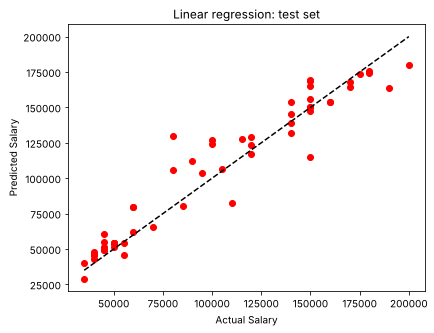

In [36]:
# Evaluate on the held-out 15% test split
from sklearn.metrics import r2_score, mean_absolute_error
X_test = df_test[['Age','Years of Experience',"Bachelor's","Master's",'PhD']]
y_test = df_test['Salary']
y_pred = model.predict(X_test)
print(f'Test R^2: {r2_score(y_test, y_pred):.3f}')
print(f'Test MAE: {mean_absolute_error(y_test, y_pred):,.0f}')

plt.scatter(y_test, y_pred, color='red')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.title('Linear regression: test set')
plt.show()
